# 02 — Sensitivity over the survey and comparison with earlier ZTF limits

**Feeds:** paper §4.1, Fig. 1. Because explosion times are uniform over the survey, the ⟨VT⟩ from explosions in any
time window is the pooled ⟨VT⟩ times the fraction of recoveries that exploded in it.

In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = False     # write PDF+PNG of each figure to figures/02/
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, save_figures=SAVE_FIGURES, fig_dir="figures/02")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"

knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
models: Bu2026Fixed, Bu2026Vary


## Monthly sensitivity and the cumulative limit (Fig. 1)

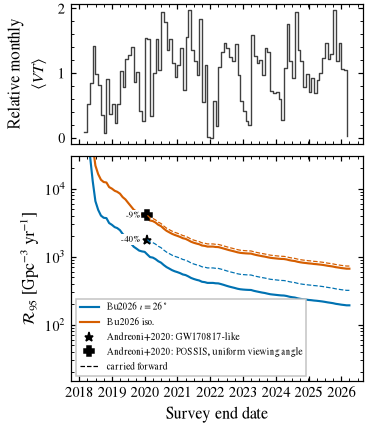

> **Result.** Monthly sensitivity ranges from 0.00 to 1.97 times the mean (first and last partial months excluded); the two weakest months are 2022-01, 2021-12.

In [2]:
SHOW_LITERATURE = ["andreoni2020_gw170817", "andreoni2020_possis_isotropic"]   # options: L.keys("rate_limits")
fig = F.sensitivity_timeline(ctx.tm, runs, M, SHOW_LITERATURE); ctx.save(fig, "sensitivity_timeline"); plt.show()
e = A.vt_by_epoch(ctx.tm, runs, FIX); rel = e.vt_month / e.vt_month.mean()
low = e.loc[rel[1:-1].nsmallest(2).index, "month"].astype(str).tolist()
NB.finding(f"Monthly sensitivity ranges from {rel[1:-1].min():.2f} to {rel.max():.2f} times the mean (first and last partial "
           f"months excluded); the two weakest months are {', '.join(low)}.")

## Our limits in Andreoni et al. (2020)'s window and over eight years

,model,published,r95_window,window_change_vs_published,vt_gain_full_over_window,duration_gain,r95_full,published_projected_full,published_duration_scaled
0,Bu2026Fixed,1775,1069,-0.3976,5.568,4.177,192,318.8,425
1,Bu2026Vary,4029,3684,-0.08573,5.551,4.177,663.6,725.8,964.6


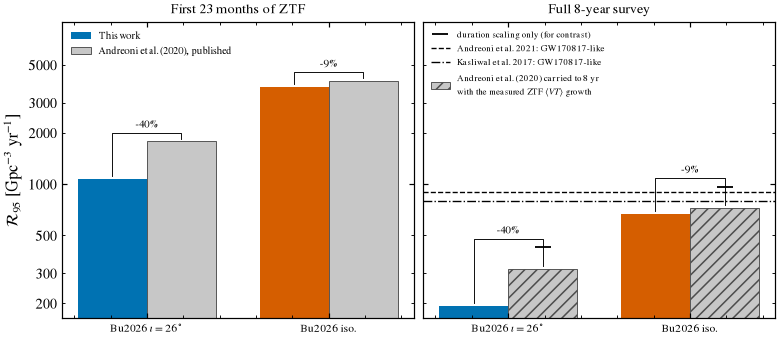

> **Result.** Over the same 23 months our limits are 40% (fixed angle) and 9% (isotropic) below the published ones. The full survey has 5.6× the window's ⟨VT⟩, against 4.2× from duration alone, so scaling a published limit by duration understates eight years of ZTF.

In [3]:
cmp = A.andreoni_comparison(ctx.tm, runs, M)
display(cmp[["model", "published", "r95_window", "window_change_vs_published", "vt_gain_full_over_window",
             "duration_gain", "r95_full", "published_projected_full", "published_duration_scaled"]])
fig = F.andreoni_window(cmp); ctx.save(fig, "andreoni_window"); plt.show()
c = cmp.set_index("model")
NB.finding(f"Over the same 23 months our limits are {100 * -c.loc[FIX, 'window_change_vs_published']:.0f}% (fixed angle) and "
           f"{100 * -c.loc[ISO, 'window_change_vs_published']:.0f}% (isotropic) below the published ones. The full survey has "
           f"{c.loc[FIX, 'vt_gain_full_over_window']:.1f}× the window's ⟨VT⟩, against {c.loc[FIX, 'duration_gain']:.1f}× from "
           "duration alone, so scaling a published limit by duration understates eight years of ZTF.")

## Is the later ZTFReST limit what the extra survey time predicts?

In [4]:
a20, a21 = L.lookup("andreoni2020_gw170817"), L.lookup("andreoni2021_ztfrest_combined")
e = e[e.vt_cumulative > 0]
upto = lambda d: e[e.month_end < pd.Timestamp(d) + pd.Timedelta(days=1)].iloc[-1].vt_cumulative   # through day d
v20, v21 = upto(a20["data_end"]), upto(a21["data_end"])
NB.finding(f"Carrying 1775 forward with our ⟨VT⟩ growth to {a21['data_end']} gives {a20['limit'] * v20 / v21:.0f}; "
           f"ZTFReST reported {a21['limit']:g}. Their improvement is about what the added survey time alone predicts.")

> **Result.** Carrying 1775 forward with our ⟨VT⟩ growth to 2021-03-03 gives 907; ZTFReST reported 900. Their improvement is about what the added survey time alone predicts.